# Week 8 Lab: Introduction to Scikit-Learn and Classification

Build a basic supervised machine learning pipeline: load the **Iris** dataset, separate features and labels, split into training and testing sets, train a **k-Nearest Neighbors** classifier, make predictions and calculate accuracy.

**Pipeline:** Load data → Features `X` / Labels `y` → Train/Test split → Train (`fit`) → Predict (`predict`) → Evaluate (accuracy)

## 1. Import Required Libraries
- `pandas`: tabular data
- `load_iris`: loads the Iris dataset
- `train_test_split`: divides data into training and testing parts
- `KNeighborsClassifier`: the k-NN algorithm
- `accuracy_score`: compares predictions with true labels

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

## 2. Load the Iris Dataset
The dataset has 150 flowers from 3 species (50 each), each described by 4 measurements.

In [2]:
iris = load_iris()

print("Feature names:", iris.feature_names)
print("Target names :", iris.target_names)
print("\nFirst 5 rows of data:\n", iris.data[:5])
print("\nFirst 5 labels:", iris.target[:5])

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names : ['setosa' 'versicolor' 'virginica']

First 5 rows of data:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

First 5 labels: [0 0 0 0 0]


In [3]:
# The same data as a table, to see what a labeled ML dataset looks like
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in iris.target]
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


| Numerical label | Species |
|---|---|
| 0 | Setosa |
| 1 | Versicolor |
| 2 | Virginica |

## 3. Separate Features and Labels
- `X` = input **features** (the four measurements)
- `y` = expected output **label** (the species)

In [4]:
X = iris.data
y = iris.target

print("X shape:", X.shape)   # (records, features)
print("y shape:", y.shape)   # (records,)

X shape: (150, 4)
y shape: (150,)


## 4. Divide Data into Training and Testing Sets
80 : 20 split. `random_state=42` makes the split reproducible; `stratify=y` keeps the class proportions the same in both parts.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 120
Testing records: 30


In [6]:
# Check that stratify=y kept 40 / 40 / 40 in training and 10 / 10 / 10 in testing
print("Training class counts:", pd.Series(y_train).value_counts().sort_index().tolist())
print("Testing  class counts:", pd.Series(y_test).value_counts().sort_index().tolist())

Training class counts: [40, 40, 40]
Testing  class counts: [10, 10, 10]


## 5. Create the Model
k-NN classifies a new flower by looking at its `k` nearest training examples and taking a majority vote. Here `k = 3`.

In [7]:
model = KNeighborsClassifier(n_neighbors=3)

## 6. Train the Model
`fit()` receives the training features and labels. For k-NN, "training" simply stores the training examples so they can be compared with new flowers at prediction time.

In [8]:
model.fit(X_train, y_train)
print("Model trained on", len(X_train), "examples.")

Model trained on 120 examples.


## 7. Make Predictions

In [9]:
y_pred = model.predict(X_test)

print("Predicted labels:")
print(y_pred)
print("\nActual labels:")
print(y_test)

Predicted labels:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Actual labels:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


## 8. Calculate Model Accuracy

$$\text{Accuracy} = \frac{\text{Correct Predictions}}{\text{Total Predictions}} \times 100$$

In [10]:
accuracy = accuracy_score(y_test, y_pred)
correct = int((y_pred == y_test).sum())

print("Correct predictions:", correct, "out of", len(y_test))
print("Model Accuracy:", accuracy * 100, "%")

Correct predictions: 30 out of 30
Model Accuracy: 100.0 %


## 9. Complete Program
All eight steps in one cell, as in the lab handout.

In [11]:
# Week 8: Introduction to Machine Learning
# Iris Flower Classification using k-NN

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()                                   # Step 2: load dataset
X = iris.data                                        # Step 3: features
y = iris.target                                      #         labels

X_train, X_test, y_train, y_test = train_test_split(  # Step 4: split
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = KNeighborsClassifier(n_neighbors=3)          # Step 5: create classifier
model.fit(X_train, y_train)                          # Step 6: train
y_pred = model.predict(X_test)                       # Step 7: predict
accuracy = accuracy_score(y_test, y_pred)            # Step 8: accuracy

print("Total Training Records:", len(X_train))
print("Total Testing Records:", len(X_test))
print("Actual Labels:   ", y_test)
print("Predicted Labels:", y_pred)
print("Model Accuracy:", accuracy * 100, "%")

Total Training Records: 120
Total Testing Records: 30
Actual Labels:    [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted Labels: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Model Accuracy: 100.0 %


## 10. Practical Exercises
### Exercise 1: Examine the Dataset

In [12]:
print("Total number of records :", len(iris.data))
print("Number of features      :", len(iris.feature_names))
print("Names of the species    :", iris.target_names.tolist())

Total number of records : 150
Number of features      : 4
Names of the species    : ['setosa', 'versicolor', 'virginica']


### Exercise 2: Change the Training / Testing Ratio (`test_size = 0.3`)

In [13]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Training records:", len(X_train2))
print("Testing records :", len(X_test2))

model2 = KNeighborsClassifier(n_neighbors=3).fit(X_train2, y_train2)
acc2 = accuracy_score(y_test2, model2.predict(X_test2))
print("Accuracy with test_size = 0.3:", round(acc2 * 100, 2), "%")

Training records: 105
Testing records : 45
Accuracy with test_size = 0.3: 95.56 %


**Observation (Exercise 2):** With `test_size = 0.3` the 150 records are split into **105 training** and **45 testing** records (instead of 120 / 30). Accuracy was **95.56 %** (43 of 45 correct), slightly below the 100 % of the 80 : 20 split. This does not mean the model got worse. It has fewer examples to learn from (105 vs 120) and is evaluated on a different, larger test set, which contains a couple of harder flowers. A larger test set also gives a more reliable accuracy estimate: with 30 test flowers each mistake costs 3.33 %, with 45 it costs 2.22 %.

### Exercise 3: Change the Number of Neighbors (k = 1, 3, 5, 7)
Each model is trained on the same 80 : 20 split from Section 4, so only `k` changes.

 k  Correct (of 30)  Accuracy (%)
 1               29         96.67
 3               30        100.00
 5               30        100.00
 7               29         96.67


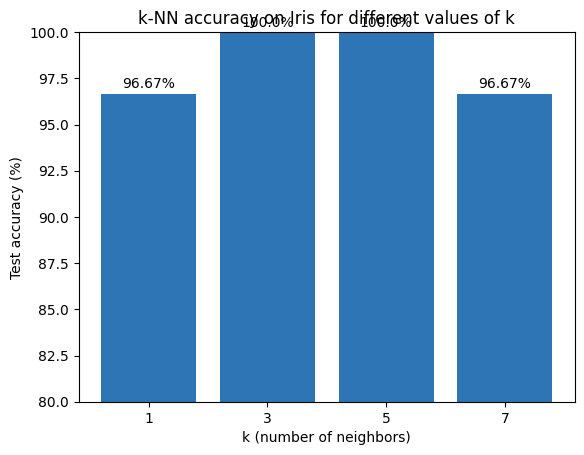

In [14]:
k_values = [1, 3, 5, 7]
rows = []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({"k": k, "Correct (of 30)": int((p == y_test).sum()), "Accuracy (%)": round(accuracy_score(y_test, p) * 100, 2)})

results = pd.DataFrame(rows)
print(results.to_string(index=False))

plt.bar([str(k) for k in k_values], results["Accuracy (%)"], color="#2E75B6")
plt.ylim(80, 100)
plt.xlabel("k (number of neighbors)")
plt.ylabel("Test accuracy (%)")
plt.title("k-NN accuracy on Iris for different values of k")
for i, v in enumerate(results["Accuracy (%)"]):
    plt.text(i, v + 0.3, f"{v}%", ha="center")
plt.show()

**Observation (Exercise 3):**

| k | Correct (of 30) | Accuracy |
|---:|---:|---:|
| 1 | 29 | 96.67 % |
| 3 | 30 | 100.00 % |
| 5 | 30 | 100.00 % |
| 7 | 29 | 96.67 % |

Yes, the accuracy changes with k, but only by one flower (3.33 %). With `k = 1` the prediction depends on a single neighbor, so one unusual or noisy training flower can cause a mistake. With very large k the vote includes distant flowers and blurs the boundary between the similar Versicolor and Virginica classes. Moderate values (k = 3 and k = 5) gave the best result here. Because the test set has only 30 flowers, a one-flower difference is weak evidence, and all four values perform well on this clean dataset.

### Exercise 4: Display Flower Species Names

In [15]:
predicted_names = iris.target_names[y_pred]
actual_names    = iris.target_names[y_test]

print("Predicted species:", predicted_names.tolist())
print("Actual species   :", actual_names.tolist())

# First 10 test flowers side by side
pd.DataFrame({"Actual": actual_names[:10], "Predicted": predicted_names[:10]})

Predicted species: ['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa']
Actual species   : ['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa']


,Actual,Predicted
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


In [16]:
# Which test flowers (if any) were misclassified?
wrong = [i for i in range(len(y_test)) if y_test[i] != y_pred[i]]
print("Misclassified:", len(wrong))
for i in wrong:
    print(f"  Test flower #{i}: actual = {actual_names[i]}, predicted = {predicted_names[i]}, features = {X_test[i]}")

Misclassified: 0


**Observation (Exercise 4):** `iris.target_names[y_pred]` converts the numeric labels (0, 1, 2) into the species names (`setosa`, `versicolor`, `virginica`), which is much easier to read. For the 80 : 20 split and k = 3, **0 of 30 test flowers were misclassified**, so the predicted and actual species match on every row.

## 11. Lab Questions

**1. What is Scikit-Learn?**
Scikit-Learn is a Python library that provides ready-made tools for machine learning: datasets, algorithms (such as k-NN and decision trees), data splitting and evaluation metrics. It lets us train models, make predictions and measure performance without programming the mathematics from scratch.

**2. What is the Iris dataset?**
A standard introductory classification dataset of measurements of 150 iris flowers belonging to three species (Setosa, Versicolor, Virginica), with 50 flowers per species. The task is to predict the species from the measurements.

**3. How many records and features are present in the Iris dataset?**
150 records and 4 features (sepal length, sepal width, petal length, petal width), confirmed by `X.shape = (150, 4)` in Section 3.

**4. What is the difference between features and labels?**
Features (`X`) are the input measurements that describe each example. The label (`y`) is the correct output the model should learn to predict. In this lab the four measurements are the features and the species is the label.

**5. Why do we divide data into training and testing sets?**
The training set is used to teach the model, and the testing set is kept aside to check how well the model performs on examples it has never seen. This gives an honest estimate of how it will behave on new data.

**6. What is the purpose of `train_test_split()`?**
It randomly divides the features and labels into a training portion and a testing portion in one call. Options like `random_state` make the split reproducible, and `stratify=y` keeps the species proportions equal in both parts.

**7. What does `test_size=0.2` mean?**
20 % of the dataset is reserved for testing and the other 80 % is used for training. For the 150 Iris records this gives 30 test records and 120 training records.

**8. What is the purpose of the `fit()` method?**
`fit(X_train, y_train)` trains the model on the training data. For k-NN it stores the training examples so they can be compared with new examples at prediction time. Other algorithms learn parameters or rules in this step.

**9. What is the purpose of the `predict()` method?**
`predict(X_test)` uses the trained model to produce a predicted label for each row of new feature data. We compare these predictions with the true labels to evaluate the model.

**10. What does the parameter `n_neighbors=3` represent?**
It sets k = 3: to classify a new flower the model finds the 3 closest training flowers (by distance in feature space) and assigns the species that most of them have (majority vote).

**11. What is meant by model accuracy?**
Accuracy is the fraction of predictions that are correct: (correct predictions ÷ total predictions) × 100. Here the model correctly classified 30 of 30 test flowers, an accuracy of 100 %.

**12. Why should a machine learning model be tested using data that was not used during training?**
A model can perform well on data it has already seen simply by memorizing it. k-NN with k = 1 would score 100 % on its own training data, because each flower is its own nearest neighbor. Testing on unseen data measures whether the model has learned patterns that generalize, which is the real goal. Testing on training data would give an overly optimistic accuracy and hide overfitting.

## 12. Lab Conclusion

In this lab we built a complete supervised machine learning pipeline with Scikit-Learn. We loaded the Iris dataset (150 flowers, 4 features, 3 species), separated features `X` from labels `y`, split the data 80 : 20 into 120 training and 30 testing records, trained a k-Nearest Neighbors classifier with k = 3, and evaluated it with accuracy.

The model classified all 30 test flowers correctly (**100 % accuracy**). The exercises showed that results depend on the choices we make: a 70 : 30 split gave 95.56 % on a larger 45-flower test set, and k = 1 and k = 7 each misclassified one flower while k = 3 and k = 5 did not. Because the Iris test set is small, such differences are only a few flowers, so conclusions should be drawn carefully.

The lab demonstrates the key idea of data-driven learning: instead of writing explicit rules (as in the Lab 1 expert system), the program learns patterns from labeled examples and applies them to previously unseen data.